**The cell below enables users to examine the correlation coefficients among Eruption Source Parameter (ESP) datasets from Aubrey, Mastin, Sparks, and IVESPA.**

**This analysis helps identify which parameters are most suitable as starting points for forecasting the remaining ESP variables using Bayesian statistical methods.**

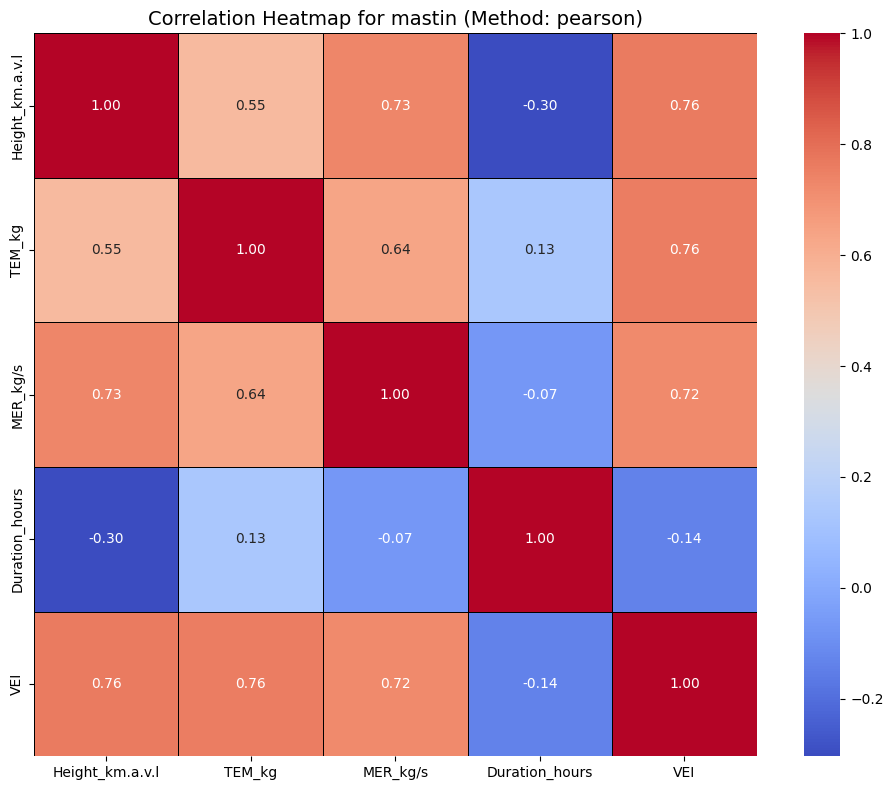

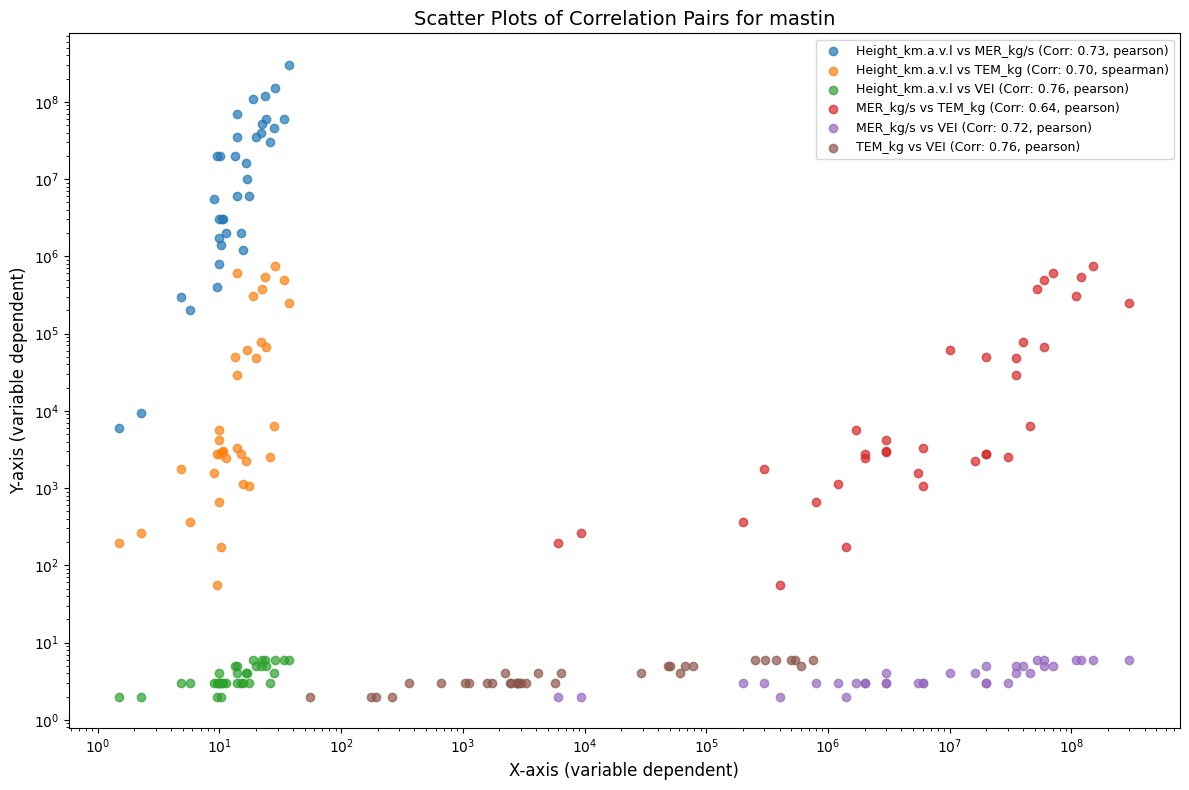

,Column1,Column2,Correlation,Method,Abs_Correlation
2,Height_km.a.v.l,MER_kg/s,0.732200,pearson,0.732200
2,Height_km.a.v.l,MER_kg/s,0.821797,spearman,0.821797
2,Height_km.a.v.l,MER_kg/s,0.658144,kendall,0.658144
1,Height_km.a.v.l,TEM_kg,0.703442,spearman,0.703442
4,Height_km.a.v.l,VEI,0.764409,pearson,0.764409
4,Height_km.a.v.l,VEI,0.759010,spearman,0.759010
4,Height_km.a.v.l,VEI,0.624731,kendall,0.624731
10,MER_kg/s,Height_km.a.v.l,0.732200,pearson,0.732200
10,MER_kg/s,Height_km.a.v.l,0.821797,spearman,0.821797
10,MER_kg/s,Height_km.a.v.l,0.658144,kendall,0.658144


In [1]:
import vei 
from vei import  analyze_correlations

load_data=vei.LOADDATA()

aubry=load_data.load_Aubry()
ivespa=load_data.load_IVESPA()
mastin=load_data.load_Mastin()
sparks=load_data.load_Sparks

analyze_correlations(dataframe =mastin, dataset_name ='mastin') # To Explore different dataset just change name of the dataframe 

In [2]:
# import python modules

import vona_trigger
import re
from esp_init import ESPInitializer
import time
import os
from tqdm import tqdm  # For progress bar
import vei 


**1. Start with Volcano Name and Location (No ESP Information is available)**

In [3]:
load_data=vei.LOADDATA()

df, vei_levels=load_data.search_whelley_2015(Volcano="taal") # uncomment this line to start with Volcano Name
#df, vei_levels=load_data.search_whelley_2015(coordinates=(14.001666	, 120.993333)) # uncomment this line to start with Volcano coordinates

df 

Top VEI values returned: [2, 3, 4]


,Volcano Number,GVP Volcano Number,Volcano,Other name or Sub-Feature,Latitude,Longitude,Elevation (m),Classification,Eruption history source,VEI 2,VEI 3,VEI 4,VEI 5,VEI 6,VEI 7,VEI 8
658,49.0,273070.0,TAAL,TALISAY CALDERA; TAAL CALDERA,14.001666,120.993333,311,Large caldera,Volcano,0.045455,0.02,0.004762,0.0,0.0,0.0,0.0


In [4]:
vei_levels

[2, 3, 4]

In [5]:

# print output base directory 

print( "Base Folder output directory Name is : ", df['Volcano'].values[0])

# Print VEI Levels with probablity values from Whelley et al., 2015 database


from rich.table import Table
from rich.console import Console


# Assuming df is your DataFrame already defined
vei_cols = [f"VEI {v}" for v in vei_levels if f"VEI {v}" in df.columns]
vei_df = df[vei_cols]

# Prepare Rich Table
table = Table(title=f"Probability VEI Levels {vei_levels} from (Whelley et al. 2015) for Volcano: {df['Volcano'].values[0]}", show_lines=True, title_style="bold blue")

# Add columns
table.add_column("Parameter", style="bold black", width=40)
table.add_column("Value", style="bold red", justify="center")


# Add each row from the filtered dataframe
for idx, row in vei_df.iterrows():
    row_str = ", ".join(f"{col}: {row[col]}" for col in vei_cols)
    table.add_row(f"Probability VEI Levels {vei_levels} from (Whelley et al. 2015)", row_str)
    table.add_row(
    "Contact Information for Software Developer",
    "Dr. Mahmud Muhammad\n"
    "[blue underline]Email:[/] [link=mailto:mahmud.muhammad@hotmail.com]mahmud.muhammad@hotmail.com[/link]\n"
    "[blue underline]Website:[/] [link=https://mahmudm.com/]https://mahmudm.com/[/link]"
)


# Print the table
console = Console()
console.print(table)


# Uncomment below to Save VEI level probability search result from Whelley et al. 2015 into .csv file

# volcano_name = df['Volcano'].values[0].strip()
# output_dir = os.path.join(volcano_name)
# os.makedirs(output_dir, exist_ok=True)
# # Save CSV file to that directory
# output_path = os.path.join(output_dir, "VEI_probability.csv")
# df.to_csv(output_path, index=False)

Base Folder output directory Name is :  TAAL


          Probability VEI Levels [2, 3, 4] from (Whelley et al. 2015) for Volcano: TAAL           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Parameter                                ┃                        Value                        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Probability VEI Levels [2, 3, 4] from    │ VEI 2: 0.045454545, VEI 3: 0.02, VEI 4: 0.004761905 │
│ (Whelley et al. 2015)                    │                                                     │
├──────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│ Contact Information for Software         │                 Dr. Mahmud Muhammad                 │
│ Developer                                │         Email: ]8;id=792103;mailto:mahmud.muhammad@hotmail.com\mahmud.muhammad@hotmail.com]8;;\          │
│                                          │            Website: ]8;id=526691;https://mahmudm.com/\https://mahmudm.com/]8;;\            │
└──────────────────────────────────────────┴─────────────────────────────────────────────────────┘

In [6]:
# Run forecasts one-by-one manually
esp = ESPInitializer(vei_levels=vei_levels, base_directory=f'{df['Volcano'].values[0]}/init')
esp.run_vei_model()
vei_df = esp.get_vei_model_dataframe()
vei_df


Generating probabilistic volumes using Bayesian updating...
✅ Probabilistic volumes successfully generated within valid VEI bounds!
Calculating mass...
✅ Mass calculation completed!
Plotting volume percentile contours...
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]\plot_percentile_contours_VEIvolume.png
Plotting mass percentile contours...
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]\plot_percentile_contours_VEImass.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]\plot_posterior_samples_histograms_VEIvolume.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]\plot_posterior_samples_histograms_VEImass.png


,VEI,Probabilistic_Bulk_Volume_m3,Probabilistic_Bulk_Volume_5th_m3,Probabilistic_Bulk_Volume_25th_m3,Probabilistic_Bulk_Volume_50th_m3,Probabilistic_Bulk_Volume_75th_m3,Probabilistic_Bulk_Volume_95th_m3,Uncertainty_Prob_Volume_m3,Mean_Mass_kg,Mass_5th_kg,Mass_25th_kg,Mass_50th_kg,Mass_75th_kg,Mass_95th_kg,Uncertainty_Mass_kg
0,2,4.093038e+06,1.198572e+06,2.096191e+06,3.549461e+06,5.711369e+06,8.753014e+06,7.554441e+06,4.092987e+09,1.198558e+09,2.096165e+09,3.549417e+09,5.711298e+09,8.752905e+09,7.554348e+09
1,3,4.089893e+07,1.198006e+07,2.096468e+07,3.549985e+07,5.698718e+07,8.751351e+07,7.553345e+07,4.089842e+10,1.197991e+10,2.096442e+10,3.549941e+10,5.698648e+10,8.751243e+10,7.553252e+10
2,4,4.094869e+08,1.199479e+08,2.098368e+08,3.555021e+08,5.707809e+08,8.754575e+08,7.555097e+08,4.094819e+11,1.199464e+11,2.098342e+11,3.554977e+11,5.707738e+11,8.754467e+11,7.555003e+11


In [8]:

# Use output from VEI model to forecast MER
percentiles=[5,50,95]
esp.forecast_mer_from_tem(
    tem_values=vei_df["Mass_50th_kg"].tolist(),
    vei_series=vei_df["VEI"].tolist(), percentiles=percentiles)

# Forecast remaining parameters from MER
esp.forecast_tem_from_mer(percentiles=percentiles)
esp.forecast_duration_from_mer(percentiles=percentiles)
esp.forecast_height_from_mer(percentiles=percentiles)
esp.forecast_particle_size_from_mer(percentiles=percentiles)

# Optional: combine all results into one DataFrame
esp.combine_results()
heights = esp.get_results_dataframe()

Model updated with xvar='TEM_kg'
Model updated with yvar='MER_kg/s'.
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_MER_kg_per_second\posterior_predictive_plot.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_MER_kg_per_second\percentiles_plot.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_MER_kg_per_second\contour_percentiles_plot.png
Saved DataFrame to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_MER_kg_per_second\forecast_MER_kg_per_second.csv
Model updated with xvar='MER_kg/s'
Model updated with yvar='MER_kg/s'.
Model updated with yvar='TEM_kg'.
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_TEM_kg\posterior_predictive_plot.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_TEM_kg\percentiles_plot.png
Saved plot to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_TEM_kg\contour_percentiles_plot.png
Saved DataFrame to TAAL/init\ESP_init_forVEI_[2, 3, 4]/Forecast_TEM_kg\forecast_TEM_kg.csv
Model updated with xvar='MER_kg/s

In [9]:
heights.columns

Index(['TEM_kg', 'MER_kg/s_Percentile_5', 'MER_kg/s_Percentile_50',
       'MER_kg/s_Percentile_95', 'Duration_hr_P5', 'Duration_hr_P50',
       'Duration_hr_P95', 'VEI', 'MER_kg/s', 'TEM_kg_Percentile_5',
       'TEM_kg_Percentile_50', 'TEM_kg_Percentile_95',
       'Duration_hours_Percentile_5', 'Duration_hours_Percentile_50',
       'Duration_hours_Percentile_95',
       'MASS_FRACTION_ASH_BELOW_63_micron_Percentile_5',
       'MASS_FRACTION_ASH_BELOW_63_micron_Percentile_50',
       'MASS_FRACTION_ASH_BELOW_63_micron_Percentile_95',
       'Height_km.a.v.l_Percentile_5', 'Height_km.a.v.l_Percentile_50',
       'Height_km.a.v.l_Percentile_95', 'Probabilistic_Bulk_Volume_m3',
       'Probabilistic_Bulk_Volume_5th_m3', 'Probabilistic_Bulk_Volume_25th_m3',
       'Probabilistic_Bulk_Volume_50th_m3',
       'Probabilistic_Bulk_Volume_75th_m3',
       'Probabilistic_Bulk_Volume_95th_m3', 'Uncertainty_Prob_Volume_m3',
       'Mean_Mass_kg', 'Mass_5th_kg', 'Mass_25th_kg', 'Mass_50th_kg',
 

In [10]:
# Run this cell to create Name Model input simulation files

from nameModel_file_generator import SimulationParameterGenerator

generator = SimulationParameterGenerator(
        vona_input=None,
        plume_input=heights ,
        output_dir=f'{df['Volcano'].values[0]}/Name_inputFiles'
    ,  VolcanoName=df['Volcano'].values[0], Longitude=df['Longitude'].values[0], Latitude=df['Latitude'].values[0], 
    Summit_Elevation=df['Elevation (m)'].values[0], Issued_date=None)

created_files = generator.run()


c:\Users\mahmu\OneDrive\Documents\GitHub\Eruption-Source-Parameters\Phase Two\nameModel_file_generator.py:41: UserWarning: VONA input is None and the following user parameters are also missing: ['Issued']. Please provide them manually.
  warnings.warn(


**2. If Plume Height known from Infrasound**


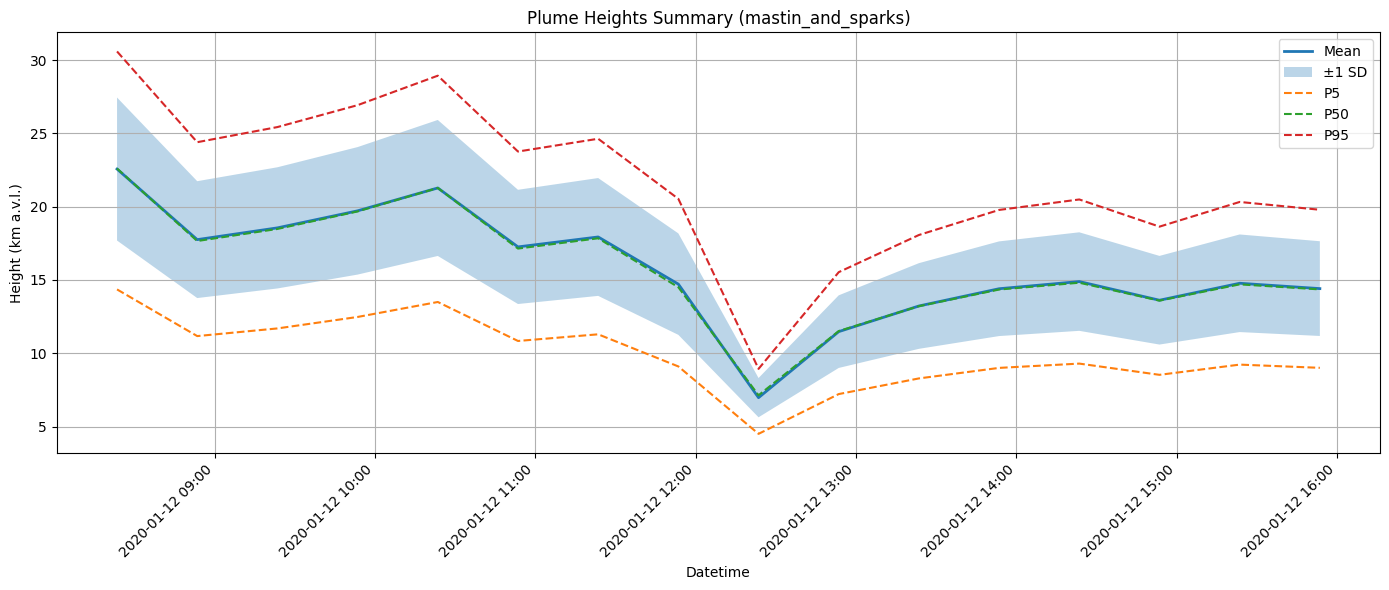

Simulation files for TAAL created in: Data_from_InfrasoundTeam\TAAL
✅ Saved summary to: Data_from_InfrasoundTeam\TAAL_auto_from_sim_20250704_190354_summary.csv
Updating metadata in TAAL_auto_from_sim_20250704_190354_summary.csv...


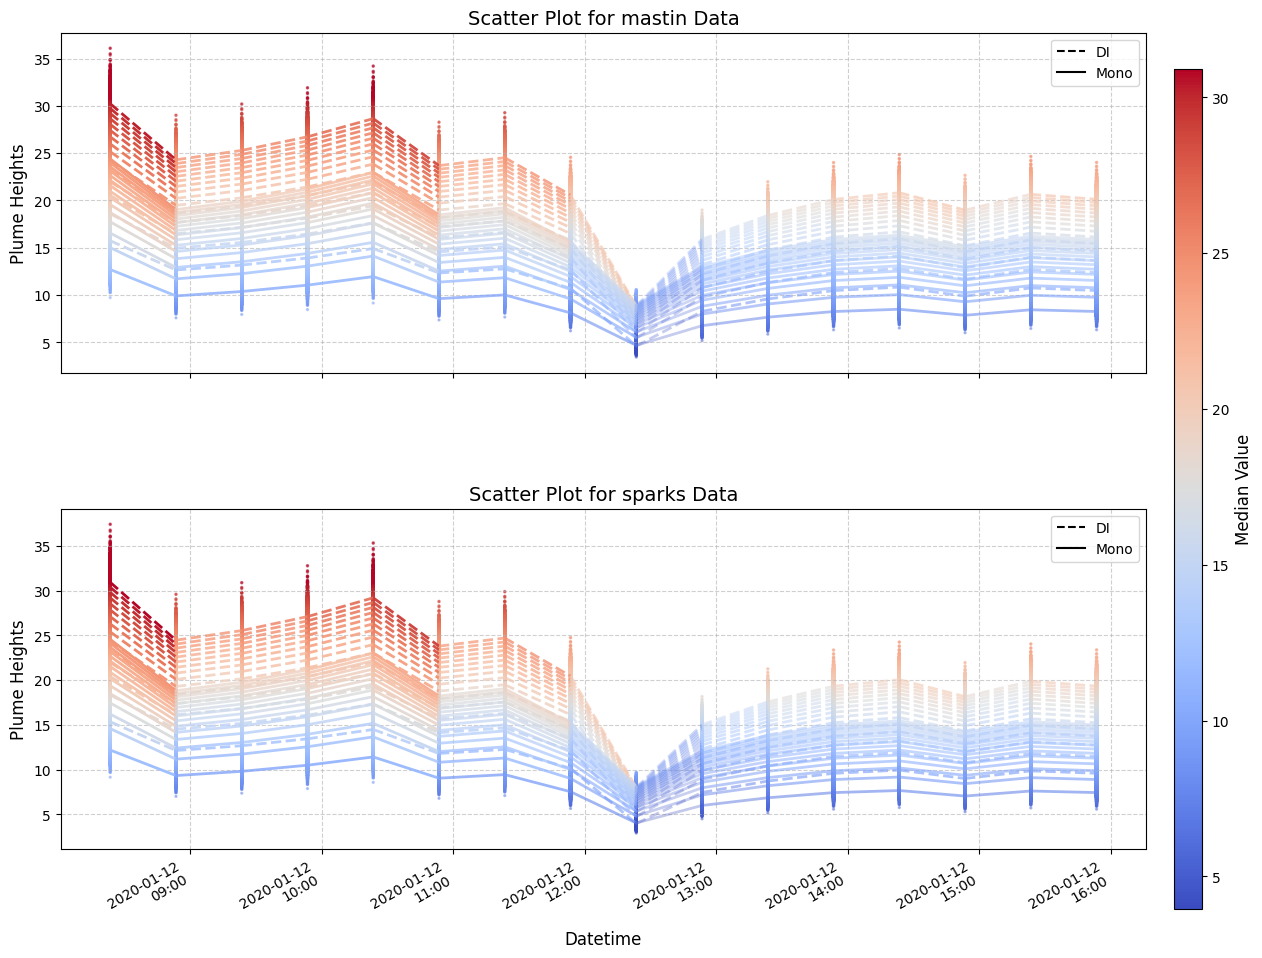

In [11]:

from vona_trigger import PlumeHeightAnalyzer_FromInfrasound

# Step 1: Initialize the analyzer
analyzer = PlumeHeightAnalyzer_FromInfrasound(folder_path='Data_from_InfrasoundTeam/allPlumeHeights', 
                                              InfraSound_DateTime_Txt_input='Data_from_InfrasoundTeam/DateTime_Taal2020.txt', 
                                              window_minutes_before=15, 
                                              window_minutes_after=15, 
                                              output_duration_format='HH_MM', output_csv_dir='Data_from_InfrasoundTeam', sim_output_dir='Data_from_InfrasoundTeam')




Infrasound_datatime_dataframe = analyzer.eruptiontime_processer(InfraSound_DateTime_Txt_input='Data_from_InfrasoundTeam/DateTime_Taal2020.txt', 
                                              window_minutes_before=15, 
                                              window_minutes_after=15, 
                                             output_duration_format='HH_MM')




# Run previous steps
plume_height_summary_df=analyzer.calculate_column_percentiles(
    dataset_name='mastin_and_sparks',
    dataset_type='both',
    use_weighted_average=True,
    plot=True)


analyzer.ensure_metadata_in_csvs_with_defaults()

analyzer.generate_sim_files_from_user_csv(
    csv_input=None,  # Will use internal data
    volcano_name="TAAL",
    latitude=-6.1,
    longitude=105.4,
    summit_elevation=1800
)


analyzer.visualize_datasets( eruption_df=Infrasound_datatime_dataframe, save_path=None)




***3. Processes plume height data from satellite-derived eruption datasets to forecast eruption source parameters (ESP)***

In [12]:
from vona_trigger import PlumeHeightAnalyzerFromSatellite


processor = PlumeHeightAnalyzerFromSatellite(
    source_excel="./DataFrom_SatelliteTeam/Ruang_Taal_eruption_details.xlsx",
    working_dir="./DataFrom_SatelliteTeam"
)

processor.extract_csvs_with_metadata()
processor.process_csvs_for_simulation(remove_zero_height=True, use_current_time=False)
processor.export_skipped_logs()

Skipped lines log exported to: DataFrom_SatelliteTeam\NameModel_Simulation_inputFiles\skipped_lines_log.csv


**4. Update Eruption Source Parameters (ESP) in realtime  from VONA Message**

In [13]:
"""
VONA ESP Processing Loop

This script continuously monitors for new VONA messages using the `vona_trigger` module.
When a new VONA alert is detected (based on changes in volcano name, ash cloud height, or VEI),
it initializes eruption source parameter (ESP) forecasting using the `ESPInitializer` class.
The output is then passed to `SimulationParameterGenerator` to create NAME model simulation input files.

Dependencies:
- vona_trigger
- re
- os
- esp_init (ESPInitializer class)
- nameModel_file_generator (SimulationParameterGenerator class)
"""
import vona_trigger
import re
from esp_init import ESPInitializer
import os
import time
from tqdm import tqdm
from rich.console import Console
from rich.panel import Panel
from rich.table import Table
from rich.text import Text
from rich import box
from nameModel_file_generator import SimulationParameterGenerator

# Initialize rich console
console = Console()

# Initialize storage for previous values
previous_values = {
    "volcano_name": None,
    "AshCloudHeight_AGL": None,
    "vei_range": None
}

def clear_screen():
    """Clears the terminal screen for a clean output."""
    os.system('cls' if os.name == 'nt' else 'clear')

def normalize_text(text):
    """Normalizes text by removing excess whitespace."""
    if isinstance(text, str):
        return re.sub(r'\s+', ' ', text).strip()
    return text

def fancy_status_panel(status: str, emoji="🔔", style="bold green"):
    """Display a highlighted status message."""
    console.print(Panel(Text(status, justify="center", style=style), title=emoji + " STATUS", style="bold blue", expand=False))

def display_change_table(prev_dict, curr_dict):
    """Pretty table showing changes."""
    table = Table(title="Change Summary", box=box.DOUBLE_EDGE, title_style="bold magenta")
    table.add_column("Field", style="cyan", justify="left")
    table.add_column("Previous", style="red")
    table.add_column("Current", style="green")

    for key in curr_dict:
        prev = normalize_text(prev_dict[key]) if prev_dict[key] is not None else "-"
        curr = normalize_text(curr_dict[key])
        if prev != curr:
            table.add_row(key, str(prev), str(curr))

    console.print(table)


# Main loop
while True:
    VONA_reports, VONA_latest_data, volcano_name, latitude, longitude, AshCloudHeight_AGL, vei_range = vona_trigger.VONA_Message(VONA_Source="MAGMA")
    VONA_latest_data.reset_index(drop=True, inplace=True)
    row = VONA_latest_data.iloc[0]
    issue_date = row.get("Issued", "_")

    current_values = {
        "volcano_name": volcano_name,
        "AshCloudHeight_AGL": AshCloudHeight_AGL,
        "vei_range": vei_range
    }

    changes_detected = False
    for key in current_values:
        prev_value = normalize_text(previous_values[key]) if previous_values[key] is not None else None
        curr_value = normalize_text(current_values[key])
        if prev_value != curr_value:
            changes_detected = True

    if changes_detected:
        clear_screen()
        fancy_status_panel("New VONA Data Detected", emoji="🌋")

        display_change_table(previous_values, current_values)
        previous_values.update(current_values)

        # Forecast using plume height (when VEI is absent)
        if AshCloudHeight_AGL is not None or vei_range is None:
            console.print("\n[bold blue]Running ESP Forecast (Plume Height)...[/bold blue]")
            esp = ESPInitializer(vei_levels=None, plume_height=AshCloudHeight_AGL, show_plots=True,
                                 base_directory=f'{volcano_name}/{issue_date}/VONA')
            esp.run_all_forecasts(percentiles=[5,50,95])
            heights = esp.get_results_dataframe()

            if heights is not None:
                generator = SimulationParameterGenerator(
                    vona_input=VONA_latest_data,
                    plume_input=heights,
                    output_dir=f'{volcano_name}_{issue_date}/VONA/Name_inputFiles'
                )
                created_files = generator.run()
                console.print("[green]✓ NAME input files created for Plume Height run.[/green]")

        # Forecast using VEI (when both inputs are present)
        if vei_range is not None : # and AshCloudHeight_AGL is not None
            console.print("\n[bold blue]Running ESP Forecast (VEI)...[/bold blue]")
            esp = ESPInitializer(vei_levels=vei_range, plume_height=None, show_plots=True,
                                 base_directory=f'{volcano_name}/{issue_date}/init')
            esp.run_all_forecasts(percentiles=[5,50,95])
            heights = esp.get_results_dataframe()

            if heights is not None:
                generator = SimulationParameterGenerator(
                    vona_input=VONA_latest_data,
                    plume_input=heights,
                    output_dir=f'{volcano_name}/{issue_date}/init/Name_inputFiles', duration_hours=1.0)
                created_files = generator.run()
                console.print("[green]✓ NAME input files created for VEI run.[/green]")

    # Wait loop with progress bar
    status_msg = "🟢 Waiting for next VONA report..." if changes_detected else "🟡 No new data - Monitoring..."
    console.print(Panel(status_msg, title="⏱ Status", expand=False, style="bold yellow" if not changes_detected else "bold green"))

    with tqdm(total=1800, desc="⏳ Refreshing in", unit="s", bar_format="{l_bar}{bar} | ETA: {remaining}") as pbar:
        for _ in range(1800):
            time.sleep(1)
            pbar.update(1)


CSV file created: ./TVAAC_Tokyo\vaa_texts.csv
Scraping up to 1 pages for All Volcanoes...


🔄 Scraping Pages: 100%|██████████| 1/1 [00:07<00:00,  7.34s/page]


Scraping completed. Data saved at Magma_VONA\vona_reports_sorted.csv
Extracting details from 15 reports...


📝 Extracting Reports:   0%|          | 0/15 [00:00<?, ?report/s]2025-07-04 19:04:59,631 - WARNING - Connection pool is full, discarding connection: magma.esdm.go.id. Connection pool size: 10
2025-07-04 19:04:59,635 - WARNING - Connection pool is full, discarding connection: magma.esdm.go.id. Connection pool size: 10
📝 Extracting Reports: 100%|██████████| 15/15 [00:02<00:00,  6.30report/s]



💾 Saving extracted reports...


...

Generating probabilistic volumes using Bayesian updating...
✅ Probabilistic volumes successfully generated within valid VEI bounds!
Calculating mass...
✅ Mass calculation completed!
Plotting volume percentile contours...
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]\plot_percentile_contours_VEIvolume.png
Plotting mass percentile contours...
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]\plot_percentile_contours_VEImass.png
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]\plot_posterior_samples_histograms_VEIvolume.png
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]\plot_posterior_samples_histograms_VEImass.png
Model updated with xvar='TEM_kg'
Model updated with yvar='MER_kg/s'.
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]/Forecast_MER_kg_per_second\posterior_predictive_plot.png
Saved plot to Semeru/20250705/0115Z/init\ESP_init_forVEI_[2]/Forecast_MER_kg_per_second\percentiles_plot.png
Saved plot to Semeru/20250705/01

✓ NAME input files created for VEI run.

╭───────────── ⏱ Status ─────────────╮
│ 🟢 Waiting for next VONA report... │
╰────────────────────────────────────╯

⏳ Refreshing in:  34%|███▍       | ETA: 19:45


KeyboardInterrupt: 